# 04 · A site-independent detector

Notebook 03 showed that our CSIC-trained detector flags about 96% of **normal** Juice Shop traffic as attacks. We want one model that works on logs from **any** site, so here we test two fixes:

1. **New features** (`value_features()` in `ml/features.py`): look only at what the user typed (URL parameter values, form/JSON body values) plus traversal and file-probe marks in the path. Path names, parameter names, JSON brackets and the HTTP method are ignored, because they change from site to site.
2. **Cleaner training labels**: drop the CSIC "anomalous" requests that carry no attack payload.

**Inputs:** `data/processed/csic_clean.csv` (from notebook 01) and `data/raw/juiceshop_normal.log` (normal lab browsing).

In [1]:
import sys, re
from pathlib import Path
from urllib.parse import quote, unquote_plus
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from ml.features import request_features
from ml.detector import build_pipeline, has_payload, to_frame
from backend.app.log_parser import parse_log

csic = pd.read_csv(ROOT / 'data' / 'processed' / 'csic_clean.csv', keep_default_na=False)
rows, _ = parse_log((ROOT / 'data' / 'raw' / 'juiceshop_normal.log').read_text(encoding='utf-8', errors='replace'))
js = pd.DataFrame(rows)
print(len(csic), 'CSIC requests,', len(js), 'normal Juice Shop requests')

25608 CSIC requests, 239 normal Juice Shop requests


A small set of attacks against our own lab (same payloads as `lab/generator/manual_examples.py`, plus two in JSON bodies). Only 8 requests, so treat this as a sanity check until the traffic generator gives us a real labelled set.

In [2]:
q = lambda s: quote(s, safe='')
lab_attacks = pd.DataFrame([
    ('sqli', 'GET', '/rest/products/search?q=' + q("')) OR 1=1--"), ''),
    ('sqli', 'GET', '/rest/products/search?q=' + q("')) UNION SELECT id,email,password,4,5,6,7,8,9 FROM Users--"), ''),
    ('xss', 'GET', '/rest/products/search?q=' + q('<script>alert(1)</script>'), ''),
    ('xss', 'GET', '/rest/products/search?q=' + q('<iframe src="javascript:alert(1)">'), ''),
    ('traversal', 'GET', '/ftp/..%252F..%252F..%252Fetc%252Fpasswd', ''),
    ('traversal', 'GET', '/ftp/..%252F..%252Fetc%252Fshadow', ''),
    ('sqli', 'POST', '/rest/user/login', '{"email":"\' OR 1=1--","password":"x"}'),
    ('xss', 'POST', '/api/Feedbacks/', '{"comment":"<img src=x onerror=alert(1)>","rating":1}'),
], columns=['type', 'method', 'path', 'body'])
lab_attacks[['type', 'method']]

,type,method
0,sqli,GET
1,sqli,GET
2,xss,GET
3,xss,GET
4,traversal,GET
5,traversal,GET
6,sqli,POST
7,xss,POST


## 1. The CSIC label problem

CSIC was made by changing normal requests. Some changes are real attacks (SQL injection, XSS, ...), but many only rename a parameter (`modoA` instead of `modo`) or put a value that is wrong only for that shop. Nothing in those requests looks like an attack; you can only tell they are wrong if you know the site.

In [3]:
Xv = to_frame(csic['Method'], csic['path'], csic['body'])
y = csic['label'].values
payload = has_payload(Xv).values
pd.crosstab(pd.Series(y, name='label (1 = anomalous)'), pd.Series(payload, name='carries a payload'))

carries a payload,False,True
label (1 = anomalous),,
0,9346,298
1,8776,7188


In [4]:
print(f'{((y == 1) & ~payload).sum() / (y == 1).sum():.0%} of CSIC anomalies carry no payload. Examples:')
csic[(y == 1) & ~payload].sample(8, random_state=3)[['Method', 'path']]

55% of CSIC anomalies carry no payload. Examples:


,Method,path
24377,GET,/tienda1/miembros/editar.jsp?modo=registro&log...
17472,GET,/tienda1/publico/anadir.jsp?id=1%2B&nombre=Que...
22095,GET,/tienda1/publico/anadir.jsp?id=3&nombre=Queso+...
22336,POST,/tienda1/publico/anadir.jsp
17945,GET,/tienda1/publico/anadir.jsp?id=2%2F&nombre=Que...
17829,GET,/tienda1/publico/anadir.jsp?id=3%2F&nombre=Que...
18956,GET,/tienda1/publico/anadir.jsp?id=2%2F&nombre=Vin...
11429,POST,/tienda1/publico/registro.jsp


With those requests in training, a clean-looking request is roughly a coin flip between normal and attack, so the model has to memorise CSIC details (value lengths, parameter names) to tell them apart. On another site those details mean nothing, and almost everything is flagged.

## 2. Experiment

Four XGBoost models, all trained on CSIC only:

| | features | training labels |
|---|---|---|
| old / all | TF-IDF + `request_features()` (the model from notebook 02) | all CSIC |
| old / payload | same | CSIC without payload-less anomalies |
| value / all | `value_features()` | all CSIC |
| value / payload | `value_features()` | CSIC without payload-less anomalies |

For each we report CSIC test F1 (20% held out, same label set as training), the false-alarm rate on normal Juice Shop traffic, and how many lab attacks it catches. Takes a few minutes.

In [5]:
def old_frame(m, p, b):
    dec = lambda s: unquote_plus(str(s or ''), encoding='latin-1')
    text = [f'{a} {dec(x)} {dec(z)}' for a, x, z in zip(m, p, b)]
    hand = pd.DataFrame([request_features(a, x, z) for a, x, z in zip(m, p, b)])
    return pd.concat([pd.DataFrame({'text': text}), hand], axis=1)

frames = {
    'old': (old_frame(csic['Method'], csic['path'], csic['body']),
            old_frame(js['method'], js['path'], js['body']),
            old_frame(lab_attacks['method'], lab_attacks['path'], lab_attacks['body'])),
    'value': (Xv, to_frame(js['method'], js['path'], js['body']),
              to_frame(lab_attacks['method'], lab_attacks['path'], lab_attacks['body'])),
}
label_sets = {'all': np.ones(len(csic), bool), 'payload': (y == 0) | payload}

results, models = [], {}
for feats, (X, Xj, Xa) in frames.items():
    cols = [c for c in X.columns if c != 'text']
    for labels, keep in label_sets.items():
        Xk, yk = X[keep].reset_index(drop=True), y[keep]
        tr, te = train_test_split(np.arange(len(yk)), test_size=0.2, stratify=yk, random_state=42)
        pw = (yk == 0).sum() / (yk == 1).sum()
        m = build_pipeline(cols, pos_weight=pw, use_tfidf=(feats == 'old')).fit(Xk.iloc[tr], yk[tr])
        pred = m.predict(Xk.iloc[te])
        models[(feats, labels)] = m
        results.append({'model': f'{feats} / {labels}',
                        'CSIC F1': f1_score(yk[te], pred),
                        'CSIC precision': precision_score(yk[te], pred),
                        'CSIC recall': recall_score(yk[te], pred),
                        'Juice Shop false alarms %': 100 * m.predict(Xj).mean(),
                        'lab attacks caught': f'{int(m.predict(Xa).sum())}/{len(Xa)}'})
        print(results[-1]['model'], 'done')
res = pd.DataFrame(results).set_index('model')
res.round(3)

old / all done


old / payload done


value / all done


value / payload done


,CSIC F1,CSIC precision,CSIC recall,Juice Shop false alarms %,lab attacks caught
model,,,,,
old / all,0.984,0.996,0.972,95.816,8/8
old / payload,0.998,0.996,0.999,91.213,8/8
value / all,0.747,0.957,0.613,99.582,8/8
value / payload,0.992,0.990,0.994,0.000,8/8


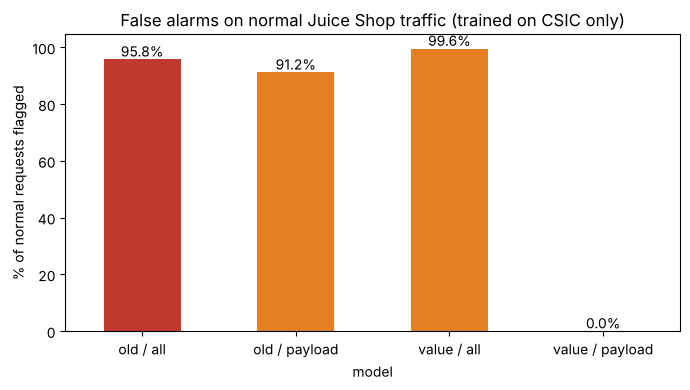

In [6]:
ax = res['Juice Shop false alarms %'].plot.bar(rot=0, figsize=(7, 4), color=['#c0392b', '#e67e22', '#e67e22', '#27ae60'])
ax.set_ylabel('% of normal requests flagged')
ax.set_title('False alarms on normal Juice Shop traffic (trained on CSIC only)')
for i, v in enumerate(res['Juice Shop false alarms %']):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.tight_layout(); plt.show()

## 3. Look closer at the chosen model (value / payload)

Highest attack probabilities among the normal Juice Shop requests (path only, no body values), and the probability for each lab attack.

In [7]:
best = models[('value', 'payload')]
Xj, Xa = frames['value'][1], frames['value'][2]
top = js.assign(attack_prob=best.predict_proba(Xj)[:, 1])
top['path'] = top['path'].str.split('?').str[0].str[:60]
display(top.sort_values('attack_prob', ascending=False)[['method', 'path', 'attack_prob']].head(8).round(3))
lab_attacks.assign(attack_prob=best.predict_proba(Xa)[:, 1].round(3))[['type', 'method', 'attack_prob']]

,method,path,attack_prob
18,POST,/socket.io/,0.219
184,POST,/api/Complaints/,0.004
84,POST,/rest/user/login,0.003
3,GET,/polyfills.js,0.003
4,GET,/chunk-1qQQGal7.js,0.003
5,GET,/chunk-Cv2YgWUq.js,0.003
1,GET,/rolldown-runtime-BoHGiXSq.js,0.003
7,GET,/scripts.js,0.003


,type,method,attack_prob
0,sqli,GET,1.0
1,sqli,GET,1.0
2,xss,GET,1.0
3,xss,GET,1.0
4,traversal,GET,1.0
5,traversal,GET,1.0
6,sqli,POST,1.0
7,xss,POST,1.0


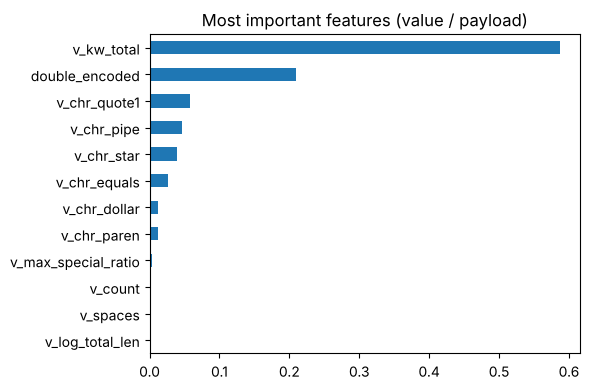

In [8]:
imp = pd.Series(best.named_steps['model'].feature_importances_,
                index=[c for c in Xv.columns if c != 'text']).sort_values(ascending=False)
imp.head(12).plot.barh(figsize=(6, 4)).invert_yaxis()
plt.title('Most important features (value / payload)'); plt.tight_layout(); plt.show()

## 4. What we learned

- **New features alone are not enough.** With all CSIC labels the model still flags almost every normal request, because the payload-less anomalies teach it that clean requests are attacks.
- **New features + payload labels work.** False alarms on normal Juice Shop traffic drop to about 0% and all lab attacks are still caught.
- **Decision:** the backend now uses `value / payload` (`ml/detector.py`, trained by `python -m ml.train_detector`).

**Limits (for the report):**
- The CSIC F1 of the payload model is optimistic: we picked its training attacks with the same signals the features measure. The fair test is a site the model never saw, which is why the Juice Shop numbers matter more.
- Only 8 lab attacks so far. The labelled traffic from `lab/generator/generate_traffic.py` will give the real recall.
- Requests that are only wrong for one site (renamed parameters, out-of-range values) are out of scope for this model. Catching those needs a per-site layer that learns that site's normal traffic.